# 01 · The volume: chunks, air and papyrus

**The problem.** Every later step reads the scan. Before tracing a sheet or detecting ink, you need to know how the
scan is stored (so that reading it is cheap), what its numbers mean (so that "bright" is not mistaken for "papyrus"),
and how a sheet looks locally (so that you can find its direction without any model).

**Data.**

| object | what it is | size here |
|---|---|---|
| PHerc. 139, the 9.362 µm scan | OME-Zarr pyramid, 6 levels, uint8, 128³ chunks | level 0 is about 920 GB |
| level 1 (18.7 µm voxels) | the same scan with every axis halved | one 256³ block, 17 MB |

**What you will measure:** the cost of a badly aligned read, the air/papyrus histogram, three orthogonal views, and the
sheet normal and its reliability (coherence) from the structure tensor.

In [1]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [2]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

## 1. How the scan is stored

```
 level 0   20,974 × 6,621 × 6,621  ─┐
 level 1   10,487 × 3,311 × 3,311   │  every level halves each axis:
 level 2    5,244 × 1,656 × 1,656   │  1/8 of the voxels of the level below
   ...                              │
 level 5      656 ×   207 ×   207  ─┘

 each level is cut into 128 × 128 × 128 chunks; a chunk is one file in the bucket,
 so a read costs one request per chunk it touches, whether you need 1 voxel of it or all 2 million
```

That last line is the practical rule: **align your reads to the chunk grid.** A 256³ block that starts on a chunk
boundary touches 2³ = 8 chunks; shift it by half a chunk and it touches 3³ = 27, more than three times the data.

In [3]:
v1 = vlab.scroll_volume(1)
zc, yc, xc = (v1.shape[0] // 2) // 128 * 128, 1536, 1536            # chunk-aligned start
for name, off in (('aligned to the chunk grid', 0), ('shifted by half a chunk', 64)):
    sl = tuple(slice(c + off, c + off + 256) for c in (zc, yc, xc))
    n = np.prod([len(range(s.start // 128, (s.stop - 1) // 128 + 1)) for s in sl])
    t = time.time(); _ = v1[sl]; dt = time.time() - t
    print(f'256³ block {name:27s}: {n:2d} chunks, {n * 128 ** 3 / 1e6:5.0f} MB fetched for 17 MB used, {dt:.1f}s (uncached)')
t = time.time(); B = vlab.crop(v1, 'v1block', slice(zc, zc + 256), slice(yc, yc + 256), slice(xc, xc + 256))
print(f'block {B.shape} {B.dtype}, {B.nbytes / 1e6:.0f} MB, from the local cache in {time.time() - t:.1f}s')

256³ block aligned to the chunk grid  :  8 chunks,    17 MB fetched for 17 MB used, 2.1s (uncached)


256³ block shifted by half a chunk    : 27 chunks,    57 MB fetched for 17 MB used, 2.4s (uncached)


block (256, 256, 256) uint8, 17 MB, from the local cache in 1.2s


## 2. What the numbers mean

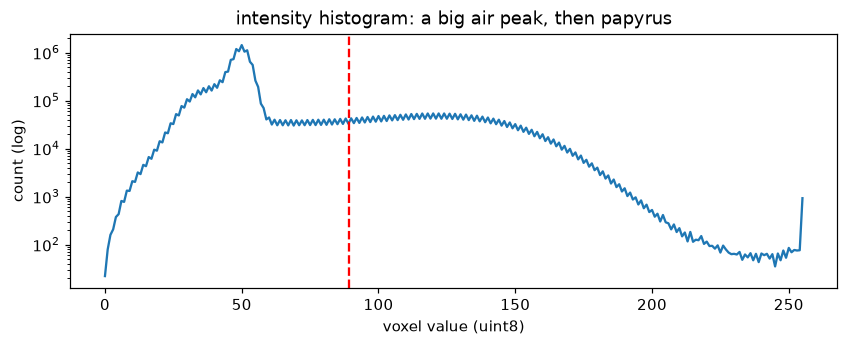

fraction above 89: 0.181


In [4]:
h = np.bincount(B.ravel(), minlength=256)
plt.figure(figsize=(9, 3)); plt.semilogy(h); plt.xlabel('voxel value (uint8)'); plt.ylabel('count (log)')
thr = 255 * 0.35
plt.axvline(thr, c='r', ls='--'); plt.title('intensity histogram: a big air peak, then papyrus'); plt.show()
print(f'fraction above {thr:.0f}: {(B > thr).mean():.3f}')

The volume is **masked** (outside the scroll is 0) and quantised to 8 bits. Air sits low; papyrus higher. Three
cautions from the challenge's *Scroll Anatomy* notes:

- **CT intensity is a reconstructed value, not a material label or a density.** The same papyrus can read brighter or
  darker in another scan, at another energy, or in another part of the same scroll.
- **Phase contrast adds fringes.** The scans use phase-contrast imaging (notebook 00), which draws bright and dark
  halos at material boundaries. A halo is not papyrus.
- **Distance in the scan is not distance on the sheet.** Two voxels a few microns apart can lie on wraps that are
  centimetres apart once unrolled.

A threshold separates air from papyrus roughly; it fails where sheets touch, which is exactly where the real models are
needed.

## 3. Three orthogonal views

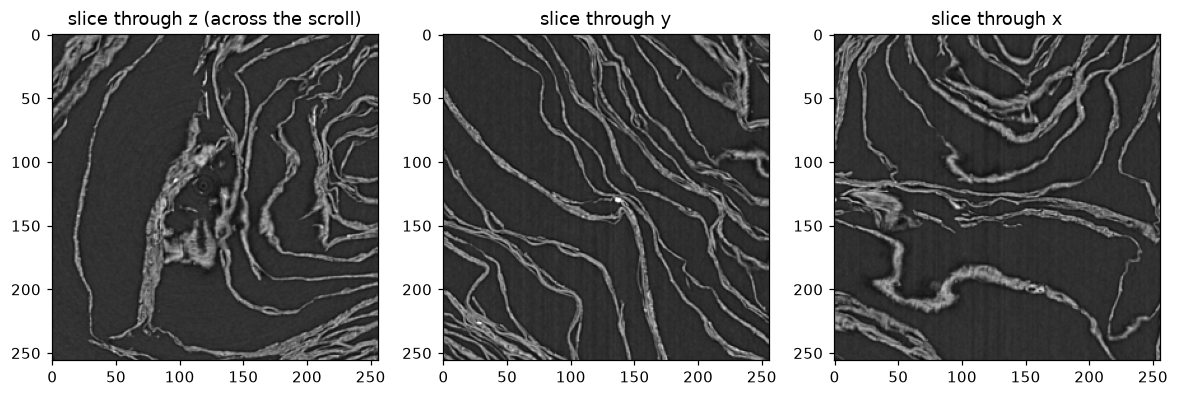

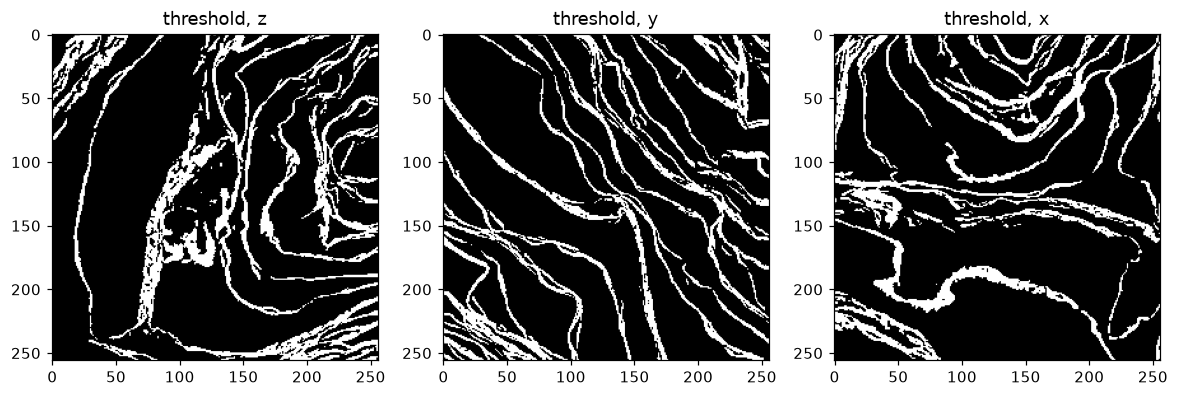

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for a, (img, t) in zip(ax, [(B[128], 'z (across the scroll)'), (B[:, 128], 'y'), (B[:, :, 128], 'x')]):
    a.imshow(img); a.set_title(f'slice through {t}')
plt.show()
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for a, (img, t) in zip(ax, [(B[128] > thr, 'z'), (B[:, 128] > thr, 'y'), (B[:, :, 128] > thr, 'x')]):
    a.imshow(img); a.set_title(f'threshold, {t}')
plt.show()

**How papyrus is built, and why that matters for the views.** A sheet is two layers of pith strips pressed together at
right angles. The faces are the **recto** (inside, written) and **verso**. A fibre stays within its own layer. In the
rolled scroll, recto fibres run around the roll and verso fibres run along its axis. Sheets (*kollemata*) were glued end
to end; at a joint (*kollesis*) two sheets overlap within **one** wrap, so "another sheet here" does not mean "another
wrap". The roll winds around a central axis, the **umbilicus**.

## 4. Sheets have a direction: the structure tensor

Locally a sheet is a thin bright layer. Its direction is the direction in which intensity changes fastest. The obvious
estimate, the gradient, fails, and the reason is the whole idea of the structure tensor.

**Counterexample: average the gradient over a sheet.** On a thin bright sheet the gradient points *into* the sheet from
both faces: up on the lower face, down on the upper face. Average it over a neighbourhood and the two cancel.

mean gradient over the patch:      (+0.0000, +0.0000)   <- the two faces cancel
structure tensor eigenvalues [0.      0.00613], top eigenvector [0. 1.]   <- points across the sheet (y)


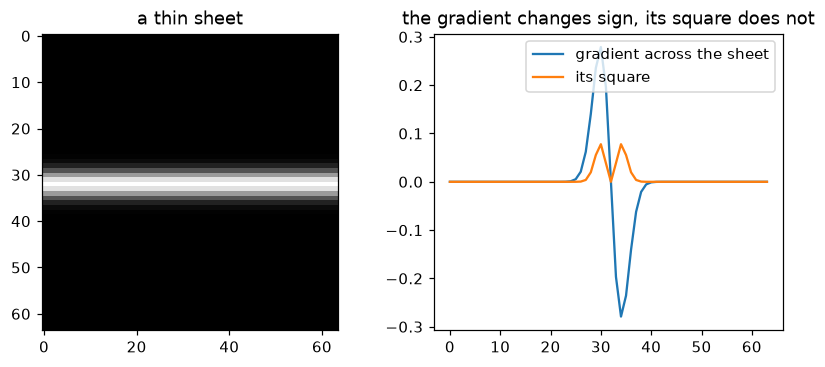

In [6]:
yy = np.arange(64)[:, None] * np.ones((1, 64)); sheet = np.exp(-0.5 * ((yy - 32) / 2.0) ** 2)   # a horizontal sheet
gy, gx = np.gradient(sheet)
print(f'mean gradient over the patch:      ({gx.mean():+.4f}, {gy.mean():+.4f})   <- the two faces cancel')
J = np.array([[np.mean(gx * gx), np.mean(gx * gy)], [np.mean(gx * gy), np.mean(gy * gy)]])
w, V = np.linalg.eigh(J)
print(f'structure tensor eigenvalues {w.round(5)}, top eigenvector {V[:, 1].round(3)}   <- points across the sheet (y)')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5)); ax[0].imshow(sheet); ax[0].set_title('a thin sheet')
ax[1].plot(gy[:, 32], label='gradient across the sheet'); ax[1].plot(gy[:, 32] ** 2, label='its square'); ax[1].legend()
ax[1].set_title('the gradient changes sign, its square does not'); plt.show()

The **structure tensor** averages the outer product g gᵀ instead of g. Squaring removes the sign, so both faces add up.
Its top eigenvector is the sheet normal (up to sign), and the gap between its eigenvalues says how sheet-like the
neighbourhood is:

| eigenvalues λ₁ ≥ λ₂ ≥ λ₃ | neighbourhood |
|---|---|
| λ₁ ≫ λ₂ ≈ λ₃ | a sheet: one strong direction |
| λ₁ ≈ λ₂ ≫ λ₃ | a fibre or a fold line: two strong directions |
| λ₁ ≈ λ₂ ≈ λ₃ | noise or a blob: no direction |

Two scales matter: the smoothing before the gradient (here 1 voxel) and the window of the average (here 3 voxels).
Too small a window sees noise; too large a window averages two wraps into one.

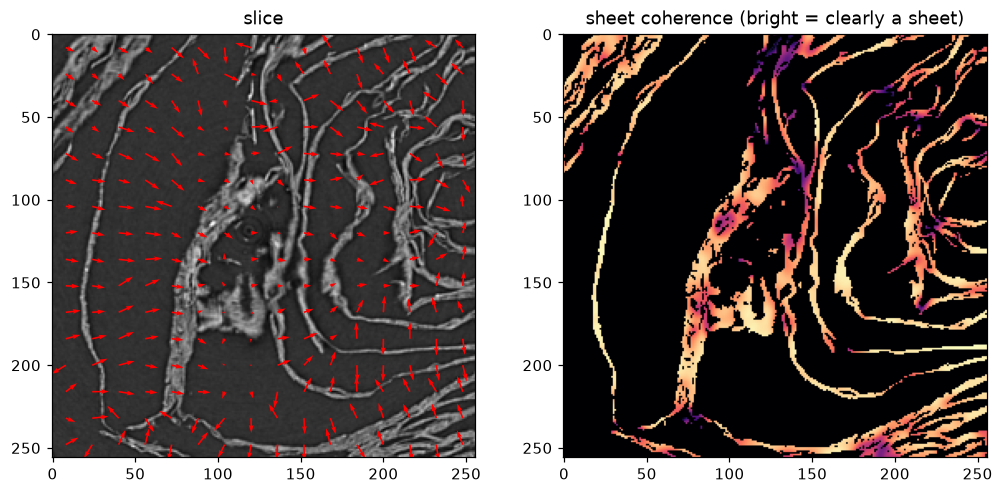

median coherence on papyrus voxels: 0.82


In [7]:
from scipy.ndimage import gaussian_filter, sobel
Bf = gaussian_filter(B.astype(np.float32), 1.0)
g = [sobel(Bf, axis=i) for i in range(3)]
J = np.empty(B.shape + (3, 3), np.float32)
for i in range(3):
    for j in range(3):
        J[..., i, j] = gaussian_filter(g[i] * g[j], 3.0)
w, v = np.linalg.eigh(J[128])                      # one z-slice, 256 x 256 tensors
coh = (w[..., 2] - w[..., 1]) / (w[..., 2] + w[..., 1] + 1e-6)   # 1 = clean sheet, 0 = isotropic
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(B[128]); ax[0].set_title('slice')
ax[1].imshow(coh * (B[128] > thr), cmap='magma'); ax[1].set_title('sheet coherence (bright = clearly a sheet)')
ys, xs = np.mgrid[8:256:16, 8:256:16]; n = v[ys, xs, :, 2]
ax[0].quiver(xs, ys, n[..., 2], -n[..., 1], color='r', scale=25); plt.show()
print(f'median coherence on papyrus voxels: {np.median(coh[B[128] > thr]):.2f}')

Red arrows: the estimated normal (in-plane part). They point across the wraps. Coherence drops where wraps touch or
the sheet is damaged: exactly where tracers go wrong.

## 5. What the challenge uses instead

| task | classical (this notebook) | what the challenge runs now |
|---|---|---|
| where is papyrus? | a threshold | **surface prediction**: 3D nnU-Net ensembles (`surface_m7_nnunet` on huggingface.co/scrollprize); the March 2026 Kaggle Surface Detection competition targeted topologically correct masks |
| which way is the sheet? | structure tensor | **lasagna normals**: predicted surface normals stored as zarr volumes, used by VC3D and the spiral fit |
| which wrap is this? | nothing local can tell | **winding constraints** + the global spiral fit (notebook 05) |

The structure tensor still matters: it needs no training data, it is fast, and it is a sanity check on any learned
normal field.

## Ideas to try

1. Compute coherence at window sizes 1, 3 and 6 and watch where neighbouring wraps merge.
2. Use the second eigenvector at a smaller scale to find **fibre** direction inside a sheet (recto vs verso).
3. Read the same block at level 0 and level 2: how does coherence change with resolution?

## Check yourself

1. Why is a global threshold not enough to separate two touching wraps?
2. Why does averaging the gradient over a sheet give almost zero, and why does the structure tensor not?
3. The structure tensor's normal has a sign ambiguity. Why does that matter when you sample "in front of" a sheet?
4. A read of a 256³ block takes 27 chunks instead of 8. What changed, and how do you avoid it?
5. Which pyramid level would you use to find the scroll's outline, and which to see fibres?